In [4]:
import pandas as pd
import numpy as np
import os
import sys
from matplotlib import pyplot as plt
%matplotlib inline

In [ ]:
!mkdir /content/Incremental-Learning-MycroftMinds-main/notebooks/other_data
!mkdir /content/Incremental-Learning-MycroftMinds-main/data/other_data

In [2]:
%cd /content/Incremental-Learning-MycroftMinds-main/notebooks/other_data

/content/Incremental-Learning-MycroftMinds-main/notebooks/other_data


In [5]:
project_root = "Incremental-Learning-MycroftMinds-main"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

### Air Quality data (Beijing 2.5)

In [8]:
data = pd.read_csv('../../data/other_data/PRSA_data_2010.1.1-2014.12.31.csv')
data.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [10]:
data.shape

(43824, 13)

In [9]:
data.isna().sum()

,0
No,0
year,0
month,0
day,0
hour,0
pm2.5,2067
DEWP,0
TEMP,0
PRES,0
cbwd,0


In [11]:
data['time'] = pd.to_datetime(data[['year', 'month', 'day', 'hour']])
data.drop(columns=['No', 'year', 'month', 'day', 'hour'], inplace=True)
display(data.head())

,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,time
0,NaN,-21,-11.0,1021.0,NW,1.79,0,0,2010-01-01 00:00:00
1,NaN,-21,-12.0,1020.0,NW,4.92,0,0,2010-01-01 01:00:00
2,NaN,-21,-11.0,1019.0,NW,6.71,0,0,2010-01-01 02:00:00
3,NaN,-21,-14.0,1019.0,NW,9.84,0,0,2010-01-01 03:00:00
4,NaN,-20,-12.0,1018.0,NW,12.97,0,0,2010-01-01 04:00:00


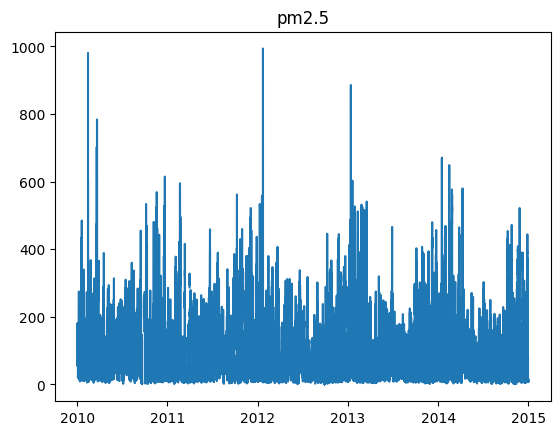

In [13]:
plt.plot(data['time'], data['pm2.5'])
plt.title('pm2.5')
plt.show()

In [14]:
data.to_csv('../../data/other_data/AQ.csv', index=False)

### Household electricity consumption data (UCI)

In [15]:
power_data = pd.read_csv('../../data/other_data/household_power_consumption.txt', delimiter=';')
power_data.head()

/tmp/ipython-input-3944319936.py:1: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  power_data = pd.read_csv('../../data/other_data/household_power_consumption.txt', delimiter=';')


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [16]:
power_data.shape

(2075259, 9)

In [17]:
power_data.isna().sum()

,0
Date,0
Time,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,25979


In [18]:
power_data['time'] = pd.to_datetime(power_data['Date'] + ' ' + power_data['Time'], dayfirst=True)
power_data.drop(columns=['Date', 'Time'], inplace=True)
power_data.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,time
0,4.216,0.418,234.840,18.400,0.000,1.000,17.0,2006-12-16 17:24:00
1,5.360,0.436,233.630,23.000,0.000,1.000,16.0,2006-12-16 17:25:00
2,5.374,0.498,233.290,23.000,0.000,2.000,17.0,2006-12-16 17:26:00
3,5.388,0.502,233.740,23.000,0.000,1.000,17.0,2006-12-16 17:27:00
4,3.666,0.528,235.680,15.800,0.000,1.000,17.0,2006-12-16 17:28:00


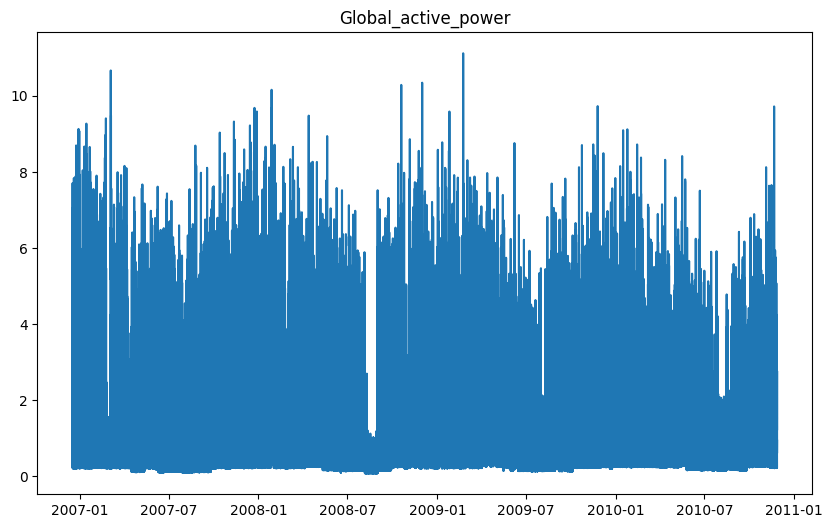

In [20]:
plt.figure(figsize=(10, 6))
power_data['Global_active_power'] = pd.to_numeric(power_data['Global_active_power'], errors='coerce')
# power_data.dropna(subset=['Global_active_power'], inplace=True)
plt.title('Global_active_power')
plt.plot(power_data['time'], power_data['Global_active_power'])
plt.show()

In [21]:
print(f"Minimum time: {power_data['time'].min()}")
print(f"Maximum time: {power_data['time'].max()}")

Minimum time: 2006-12-16 17:24:00
Maximum time: 2010-11-26 21:02:00


In [22]:
power_data.to_csv('../../data/other_data/electricity.csv', index=False)

### Synthetic data (Friedman #1)

In [23]:
def friedman1_timeseries_datetime(
    n_samples=1000,
    noise_std=1.0,
    start="2000-01-01",
    freq="D",
    seed=42
):
    """
    Generate Friedman #1 dataset as a time series with datetime index.
    """
    rng = np.random.default_rng(seed)
    n_features = 10

    # Initialize features
    X = np.zeros((n_samples, n_features))
    X[0] = rng.uniform(0, 1, size=n_features)

    # Autoregressive feature evolution
    for t in range(1, n_samples):
        X[t] = 0.9 * X[t-1] + 0.1 * rng.uniform(0, 1, size=n_features)
        X[t] = np.clip(X[t], 0, 1)

    # Compute Friedman #1 target
    y = (
        10 * np.sin(np.pi * X[:, 0] * X[:, 1])
        + 20 * (X[:, 2] - 0.5) ** 2
        + 10 * X[:, 3]
        + 5 * X[:, 4]
    )
    y += rng.normal(0, noise_std, size=n_samples)

    # Build DataFrame with datetime index
    dates = pd.date_range(start=start, periods=n_samples, freq=freq)
    data = pd.DataFrame(X, columns=[f"x{i+1}" for i in range(n_features)], index=dates)
    data["y"] = y
    data.index.name = "time"
    return data

# Example usage
df = friedman1_timeseries_datetime(n_samples=50000, freq="H")
df = df.reset_index()
df.head()


/tmp/ipython-input-3115163328.py:33: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start=start, periods=n_samples, freq=freq)


,time,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,y
0,2000-01-01 00:00:00,0.773956,0.438878,0.858598,0.697368,0.094177,0.975622,0.761140,0.786064,0.128114,0.450386,19.027630
1,2000-01-01 01:00:00,0.733640,0.487667,0.837125,0.709907,0.129101,0.900784,0.740484,0.713840,0.198065,0.468514,17.572464
2,2000-01-01 02:00:00,0.736085,0.474353,0.850482,0.728229,0.194029,0.830169,0.713108,0.646836,0.193688,0.489967,18.751122
3,2000-01-01 03:00:00,0.736953,0.523669,0.798016,0.692452,0.221582,0.766100,0.654789,0.629723,0.197010,0.507952,19.548968
4,2000-01-01 04:00:00,0.706973,0.554570,0.788241,0.654443,0.282650,0.769966,0.628058,0.595583,0.245559,0.471132,17.477635


In [24]:
df.shape

(50000, 12)

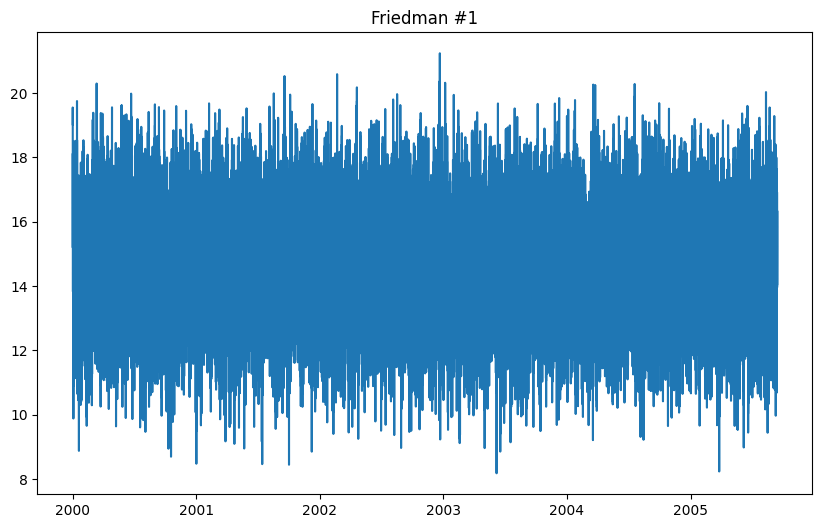

In [25]:
plt.figure(figsize=(10, 6))
plt.title('Friedman #1')
plt.plot(df['time'], df['y'])
plt.show()

In [26]:
df.to_csv('../../data/other_data/friedman.csv', index=False)

#### Thoughts on Friedman #1 data

1. We can experiment with any number of samples. I'd suggest at least having 10k samples to have enough data points for getting WFV splits.

2. Since it is a synthetic data, we should not use any of the time components (week, day, etc.) as features. Also, we should not use any sort of aggregation on it. They are only generated above so that our dataloader can work with it to get splits.

3. The target is 'y' and other features x1, x2...